# Sieci neuronowe – lista 5, część 1: sieci konwolucyjne (CNN)

Punkt wyjścia to **baseline z listy 4**: MLP 3072-512-512-10 na CIFAR10, SGD lr = 0.01, 20 epok.
Wynik: accuracy walidacyjne 0.543, testowe **0.5335 ± 0.0027** (3 seedy).

**Część 1.** Ten sam zbiór (CIFAR10), ten sam podział i ta sama normalizacja, ale sieć z warstwami `Conv2d`.
Badam po kolei trzy parametry, za każdym razem zmieniając tylko jeden, a resztę zostawiając jak w konfiguracji referencyjnej:

| parametr | wartości | referencja |
|---|---|---|
| liczba kanałów wyjściowych (pierwszej) warstwy konwolucyjnej | 8, 16, 32, 64 | 32 |
| liczba warstw konwolucyjnych | 1, 2, 3 | 2 |
| rozmiar filtra | 3×3, 5×5, 7×7 | 3×3 |

Patrzę na trzy rzeczy: wynik względem baseline'u, koszt obliczeniowy (czas epoki, liczba wag) i **overfitting**
(rosnący koszt walidacyjny, różnica accuracy trening/walidacja).

**Część 2.** Na sieci referencyjnej (najwyraźniejszy overfitting) testuję regularyzację: **Dropout** przed ostatnią warstwą,
**AdamW** z weight decay i **BatchNorm**. Celem jest mniejszy overfitting, który daje lepszy wynik na walidacji.
Na końcu najlepszy wariant porównuję z siecią bez regularyzacji i z MLP z listy 4 na zbiorze testowym (3 seedy).

## Konfiguracja

Wszystko liczę na CPU (8 wątków). Sprawdziłem wcześniej, że kilka przebiegów równolegle daje tylko ok. 15–20% przyspieszenia,
więc przebiegi idą po kolei, a zmierzony czas epoki jest porównywalny między konfiguracjami.

In [1]:
import os, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

torch.set_num_threads(8)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"torch {torch.__version__}, urządzenie: {device}, wątki: {torch.get_num_threads()}")

torch 2.15.0+cpu, urządzenie: cpu, wątki: 8


## Jak działają `Conv2d` i `MaxPool2d`: sprawdzenie na małych przykładach

Zanim zbuduję sieć, sprawdzam, że rozumiem, co liczą te warstwy (tak jak w liście 4 sprawdzałem `Linear` i koszt).

**Conv2d.** Filtr ma tyle kanałów, ile wejście (dla RGB 3). Wynik w jednym miejscu to suma iloczynów filtra i fragmentu obrazka
po wszystkich kanałach, plus bias. Filtr przesuwa się po obrazku, więc obrazek 1×3×6×6 i filtr 1×3×3×3 dają wynik 1×1×4×4
(jak na rysunku z treści zadania). Każdy filtr daje jeden kanał wyjściowy, więc `out_channels` = liczba filtrów,
czyli to samo co liczba neuronów w warstwie ukrytej MLP.

In [2]:
rng = np.random.default_rng(0)
img = rng.integers(0, 10, size=(1, 3, 6, 6)).astype(np.float32)     # 1 obrazek, 3 kanały, 6x6
filt = rng.integers(0, 4, size=(1, 3, 3, 3)).astype(np.float32)     # 1 filtr 3x3 na 3 kanały

# ręcznie: suma iloczynów filtra i każdego fragmentu 3x3 (po wszystkich kanałach)
manual = np.zeros((4, 4), dtype=np.float32)
for i in range(4):
    for j in range(4):
        manual[i, j] = (img[0, :, i:i + 3, j:j + 3] * filt[0]).sum()

conv = nn.Conv2d(in_channels=3, out_channels=1, kernel_size=3, bias=False)
with torch.no_grad():
    conv.weight.copy_(torch.tensor(filt))
    out = conv(torch.tensor(img))
print("kształt wyjścia:", tuple(out.shape))
print("ręcznie:\n", manual.astype(int))
print("Conv2d:\n", out[0, 0].numpy().astype(int))
print("identyczne:", np.array_equal(manual, out[0, 0].numpy()))

kształt wyjścia: (1, 1, 4, 4)
ręcznie:
 [[208 245 241 220]
 [217 226 239 261]
 [255 240 233 267]
 [234 212 214 231]]
Conv2d:
 [[208 245 241 220]
 [217 226 239 261]
 [255 240 233 267]
 [234 212 214 231]]
identyczne: True


**MaxPool2d(2).** Dzieli każdy kanał na okienka 2×2 i z każdego bierze maksimum, więc wysokość i szerokość spadają o połowę,
a liczba kanałów się nie zmienia. Sprawdzam na przykładzie z treści zadania (wynik powinien być 22 23 11 / 24 7 1 / 13 13 13):

In [3]:
x = torch.tensor([[-19, 22, -20, -12, -17, 11],
                  [16, -30, -1, 23, -7, -14],
                  [-14, 24, 7, -2, 1, -7],
                  [-15, -10, -1, -1, -15, 1],
                  [-13, 13, -11, -5, 13, -7],
                  [-18, 9, -18, 13, -3, 4]], dtype=torch.float32).reshape(1, 1, 6, 6)
print(nn.MaxPool2d(2)(x)[0, 0].int())

tensor([[22, 23, 11],
        [24,  7,  1],
        [13, 13, 13]], dtype=torch.int32)


**Padding.** Bez paddingu filtr k×k zmniejsza obrazek o k − 1 (6×6 → 4×4). Używam `padding = k // 2`
(dopisanie zer dookoła), dzięki czemu konwolucja nie zmienia rozmiaru, a zmniejsza go tylko pooling. Wtedy sieci z różnymi
filtrami mają ten sam rozmiar wyjścia i różnią się tylko filtrem.

**LazyLinear.** Po spłaszczeniu liczba cech zależy od kanałów, liczby warstw i paddingu. `LazyLinear` nie wymaga jej podawania:
wagi tworzy przy pierwszym przejściu danych. Dlatego w konstruktorze sieci przepuszczam jeden sztuczny obrazek
(w trybie `eval`, żeby nie ruszyć statystyk BatchNorm) i dopiero potem tworzę optymalizator.

In [4]:
lazy = nn.LazyLinear(10)
print("przed pierwszym przejściem:", lazy.weight.__class__.__name__)
lazy(torch.zeros(1, 4096))
print("po pierwszym przejściu:   ", lazy.weight.__class__.__name__, tuple(lazy.weight.shape))

przed pierwszym przejściem: UninitializedParameter
po pierwszym przejściu:    Parameter (10, 4096)


## Dane: CIFAR10, ten sam podział co w liście 4

- 5000 obrazków ze zbioru treningowego (po 500 z każdej klasy, `random_state=67`) to **walidacja**: na niej porównuję konfiguracje i wybieram epokę;
- normalizacja każdego kanału RGB średnią i odchyleniem liczonymi tylko z treningu;
- **zbiór testowy** jest użyty tylko na końcu.

Żeby nie trzymać 340 MB drugi raz, biorę pobrany już zbiór z `lab4/data` (a jeśli go nie ma, pobiera się do `lab5/data`).

In [5]:
root = "../lab4/data" if os.path.isdir("../lab4/data") else "data"
cifar_train = datasets.CIFAR10(root=root, train=True, download=True)
cifar_test = datasets.CIFAR10(root=root, train=False, download=True)
classes = cifar_train.classes

Xc = torch.tensor(cifar_train.data, dtype=torch.float32) / 255          # (50000, 32, 32, 3)
yc = torch.tensor(cifar_train.targets)
Xc_test = torch.tensor(cifar_test.data, dtype=torch.float32) / 255
yc_test = torch.tensor(cifar_test.targets)

idx_tr, idx_val = train_test_split(np.arange(len(yc)), test_size=5000, stratify=yc.numpy(), random_state=67)
mean, std = Xc[idx_tr].mean(dim=(0, 1, 2)), Xc[idx_tr].std(dim=(0, 1, 2))
prep = lambda x: ((x - mean) / std).permute(0, 3, 1, 2).contiguous()     # -> (N, 3, 32, 32), tak jak chce Conv2d
train_ds = TensorDataset(prep(Xc[idx_tr]), yc[idx_tr])
val_ds = TensorDataset(prep(Xc[idx_val]), yc[idx_val])
test_ds = TensorDataset(prep(Xc_test), yc_test)
del Xc, Xc_test

# do metryk treningowych po każdej epoce: stałe 10 000 obrazków treningowych (pełne 45 000 to +1/3 czasu epoki)
sub = np.random.default_rng(0).choice(len(train_ds), 10_000, replace=False)
train_eval_ds = TensorDataset(train_ds.tensors[0][sub], train_ds.tensors[1][sub])

BS = 128
val_loader = DataLoader(val_ds, batch_size=1000)
test_loader = DataLoader(test_ds, batch_size=1000)
train_eval_loader = DataLoader(train_eval_ds, batch_size=1000)
print(f"trening {len(train_ds)}, walidacja {len(val_ds)}, test {len(test_ds)}, kształt obrazka {tuple(train_ds[0][0].shape)}")
print("średnie kanałów RGB:", mean.numpy().round(4), " odchylenia:", std.numpy().round(4))

trening 45000, walidacja 5000, test 10000, kształt obrazka (3, 32, 32)
średnie kanałów RGB: [0.4913 0.4822 0.4465]  odchylenia: [0.247  0.2433 0.2616]


## Sieć konwolucyjna

Budowa (jak w treści zadania):

`[Conv2d → (BatchNorm) → ReLU → MaxPool 2×2] × liczba warstw → Flatten → LazyLinear(256) → ReLU → (Dropout) → Linear(10)`

- parametr „liczba kanałów” to liczba kanałów **pierwszej** warstwy konwolucyjnej; każda kolejna ma 2 razy więcej
  (32 → 64 → 128). Pooling zmniejsza obrazek 2 razy, więc tak kompensuje się utratę rozdzielczości (standardowy schemat);
- przed ostatnią warstwą jest jedna warstwa ukryta (256 neuronów), żeby Dropout „przed ostatnią warstwą” miał co wyłączać;
- BatchNorm i Dropout są wyłączone w części 1 (`batchnorm=False`, `dropout=0`), włączam je dopiero w części 2.

In [6]:
class CNN(nn.Module):
    def __init__(self, channels=32, n_conv=2, kernel=3, dropout=0.0, batchnorm=False):
        super().__init__()
        layers, c_in = [], 3
        for i in range(n_conv):
            c_out = channels * 2 ** i
            layers.append(nn.Conv2d(c_in, c_out, kernel_size=kernel, padding=kernel // 2))
            if batchnorm:
                layers.append(nn.BatchNorm2d(c_out))
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
            c_in = c_out
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.LazyLinear(256), nn.ReLU(),
            nn.Dropout(dropout),                 # p = 0 -> nic nie robi
            nn.Linear(256, 10))
        self.eval()                              # jeden sztuczny obrazek: LazyLinear ustala rozmiar wejścia
        with torch.no_grad():
            self(torch.zeros(1, 3, 32, 32))
        self.train()

    def forward(self, x):
        return self.classifier(self.features(x))


n_params = lambda m: sum(p.numel() for p in m.parameters())

m = CNN()
print(m)
x = torch.zeros(1, 3, 32, 32)
for layer in list(m.features) + list(m.classifier):
    x = layer(x)
    print(f"{layer.__class__.__name__:<12} -> {tuple(x.shape)}")
print(f"parametrów: {n_params(m):,}   (MLP z listy 4: 1,841,162)")

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)
Conv2d       -> (1, 32, 32, 32)
ReLU         -> (1, 32, 32, 32)
MaxPool2d    -> (1, 32, 16, 16)
Conv2d       -> (1, 64, 16, 16)
ReLU         -> (1, 64, 16, 16)
MaxPool2d    -> (1, 64, 8, 8)
Flatten      -> (1, 4096)
Linear       -> (1, 256)
ReLU         -> (1, 256)
Dropout      -> (1, 256)
Linear       -> (1, 10)
parametrów: 1,070,794   (MLP z listy 4: 1,841,

### Uczenie i ewaluacja

- koszt: `CrossEntropyLoss` (softmax + entropia krzyżowa), jak w liście 4;
- optymalizator: ADAM lr = 0.001 (w części 2 także AdamW). W liście 4 ADAM dla MLP przeuczał się szybciej niż SGD,
  a tu właśnie chcę wyraźnie zobaczyć overfitting;
- paczki po 128, kolejność losowana generatorem z seedem, 20 epok;
- **tryby `train` / `eval`**: `model.train()` przed przejściem danych, backward i update wag, `model.eval()` (i `no_grad`)
  przy liczeniu wszystkich metryk. W części 1 nie ma to jeszcze znaczenia (brak Dropout i BatchNorm), ale pętla jest od początku napisana poprawnie;
- po każdej epoce liczę koszt i accuracy na walidacji i na 10 000 obrazków treningowych (oba w trybie `eval`);
- zapamiętuję wagi z epoki o najlepszym accuracy walidacyjnym (jak w liście 4).

In [7]:
EPOCHS = 20
loss_fn = nn.CrossEntropyLoss()


def evaluate(loader, model):
    model.eval()
    total, preds = 0.0, []
    with torch.no_grad():
        for X, y in loader:
            out = model(X)
            total += loss_fn(out, y).item() * len(y)
            preds.append(out.argmax(1))
    preds = torch.cat(preds)
    return total / len(loader.dataset), (preds == loader.dataset.tensors[1]).float().mean().item(), preds


def fit(cfg, seed=0, epochs=EPOCHS):
    # cfg: parametry CNN + opcjonalnie wd (wtedy AdamW zamiast Adam)
    cfg = dict(cfg)
    wd = cfg.pop("wd", None)
    torch.manual_seed(seed)
    model = CNN(**cfg)
    if wd is None:
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    else:
        optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=wd)
    loader = DataLoader(train_ds, batch_size=BS, shuffle=True, generator=torch.Generator().manual_seed(seed))
    h = {"loss": [], "acc": [], "val_loss": [], "val_acc": []}
    best = (0.0, 0, None)
    t_train = 0.0
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        model.train()
        for X, y in loader:
            loss = loss_fn(model(X), y)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
        t_train += time.time() - t0
        l, a, _ = evaluate(train_eval_loader, model)
        vl, va, _ = evaluate(val_loader, model)
        for k, v in zip(h, [l, a, vl, va]):
            h[k].append(v)
        if va > best[0]:
            best = (va, epoch, copy.deepcopy(model.state_dict()))
    model.load_state_dict(best[2])
    model.eval()
    return {"model": model, "h": h, "best_acc": best[0], "best_epoch": best[1],
            "s_per_epoch": t_train / epochs, "params": n_params(model)}


def summary(runs):
    rows = {}
    for name, r in runs.items():
        h = r["h"]
        i_min = int(np.argmin(h["val_loss"]))
        rows[name] = {"parametrów": r["params"], "s / epokę": round(r["s_per_epoch"], 1),
                      "najlepsze acc walid.": round(r["best_acc"], 4), "epoka": r["best_epoch"],
                      "min koszt walid.": round(h["val_loss"][i_min], 3), "epoka min kosztu": i_min + 1,
                      "koszt walid. na końcu": round(h["val_loss"][-1], 3),
                      "acc trening na końcu": round(h["acc"][-1], 4), "acc walid. na końcu": round(h["val_acc"][-1], 4),
                      "różnica acc tr.−wal.": round(h["acc"][-1] - h["val_acc"][-1], 4)}
    df = pd.DataFrame(rows).T.apply(pd.to_numeric)
    return df.astype({"parametrów": int, "epoka": int, "epoka min kosztu": int})


def plot_runs(runs, title, baseline_val=None):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    ep = np.arange(1, EPOCHS + 1)
    for name, r in runs.items():
        h = r["h"]
        line, = axes[0].plot(ep, h["loss"], label=f"{name}: trening")
        axes[0].plot(ep, h["val_loss"], ls="--", color=line.get_color(), label=f"{name}: walidacja")
        line, = axes[1].plot(ep, h["acc"], label=f"{name}: trening")
        axes[1].plot(ep, h["val_acc"], ls="--", color=line.get_color())
    if baseline_val is not None:
        axes[1].axhline(baseline_val, color="gray", ls=":", label=f"MLP z listy 4 (walidacja {baseline_val})")
    axes[0].set_ylabel("koszt (entropia krzyżowa)"); axes[1].set_ylabel("accuracy")
    axes[0].set_ylim(0, 2.5)
    for ax in axes:
        ax.set_xlabel("epoka"); ax.grid(alpha=0.4); ax.legend(fontsize=8)
    fig.suptitle(title + "   (linia ciągła: trening, przerywana: walidacja)")
    fig.tight_layout()
    plt.show()


MLP_VAL = 0.543           # baseline z listy 4: najlepsze accuracy walidacyjne MLP (SGD, seed 0)

---
# CZĘŚĆ 1 – kanały, liczba warstw i rozmiar filtra

Konfiguracja referencyjna: **32 kanały, 2 warstwy konwolucyjne, filtr 3×3** (ok. 1 mln wag, ok. 20 s na epokę).
Wybrałem ją jako środek: jest tania, a duża warstwa liniowa (64 · 8 · 8 = 4096 wejść × 256) daje miejsce na overfitting.
Każdą konfigurację uczę na seedzie 0; referencja jest liczona raz i używana we wszystkich trzech porównaniach.

In [8]:
REF = dict(channels=32, n_conv=2, kernel=3)
SCANS = {"channels": [8, 16, 32, 64], "n_conv": [1, 2, 3], "kernel": [3, 5, 7]}

cache = {}
def run(cfg, seed=0):
    key = (tuple(sorted(cfg.items())), seed)
    if key not in cache:
        t0 = time.time()
        cache[key] = fit(cfg, seed)
        r = cache[key]
        print(f"{cfg} seed {seed}: najlepsze acc walid. {r['best_acc']:.4f} (epoka {r['best_epoch']}), {time.time() - t0:.0f} s")
    return cache[key]

scan_runs = {}
for param, values in SCANS.items():
    scan_runs[param] = {}
    for v in values:
        cfg = {**REF, param: v}
        label = {"channels": f"{v} kanałów", "n_conv": f"{v} warstw(y) conv", "kernel": f"filtr {v}×{v}"}[param]
        scan_runs[param][label] = run(cfg)

{'channels': 8, 'n_conv': 2, 'kernel': 3} seed 0: najlepsze acc walid. 0.6800 (epoka 16), 104 s


{'channels': 16, 'n_conv': 2, 'kernel': 3} seed 0: najlepsze acc walid. 0.7000 (epoka 14), 194 s


{'channels': 32, 'n_conv': 2, 'kernel': 3} seed 0: najlepsze acc walid. 0.7366 (epoka 6), 416 s


{'channels': 64, 'n_conv': 2, 'kernel': 3} seed 0: najlepsze acc walid. 0.7372 (epoka 10), 915 s


{'channels': 32, 'n_conv': 1, 'kernel': 3} seed 0: najlepsze acc walid. 0.6796 (epoka 12), 237 s


{'channels': 32, 'n_conv': 3, 'kernel': 3} seed 0: najlepsze acc walid. 0.7582 (epoka 8), 412 s


{'channels': 32, 'n_conv': 2, 'kernel': 5} seed 0: najlepsze acc walid. 0.7334 (epoka 11), 444 s


{'channels': 32, 'n_conv': 2, 'kernel': 7} seed 0: najlepsze acc walid. 0.7264 (epoka 6), 575 s


## 1a. Liczba kanałów wyjściowych

,parametrów,s / epokę,najlepsze acc walid.,epoka,min koszt walid.,epoka min kosztu,koszt walid. na końcu,acc trening na końcu,acc walid. na końcu,różnica acc tr.−wal.
8 kanałów,266362,4.5,0.6800,16,0.966,9,1.590,0.9396,0.6596,0.2800
16 kanałów,532202,8.4,0.7000,14,0.910,6,2.084,0.9831,0.6908,0.2923
32 kanałów,1070794,18.2,0.7366,6,0.816,5,2.028,0.9788,0.7116,0.2672
64 kanałów,2175626,40.1,0.7372,10,0.806,5,2.052,0.9799,0.7132,0.2667


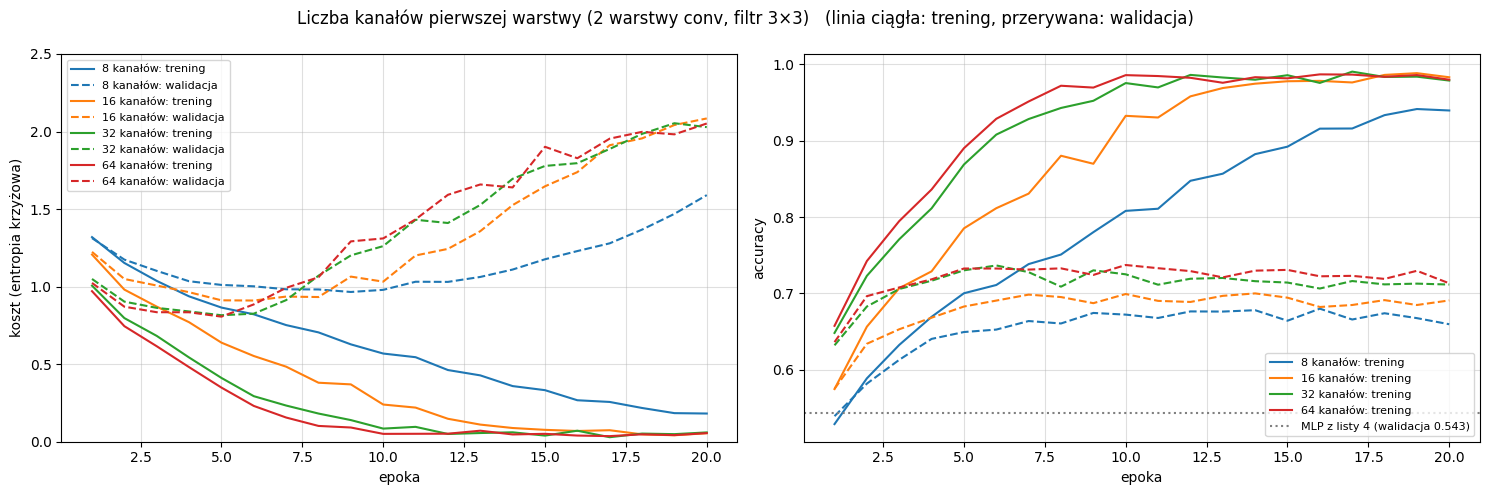

In [9]:
display(summary(scan_runs["channels"]))
plot_runs(scan_runs["channels"], "Liczba kanałów pierwszej warstwy (2 warstwy conv, filtr 3×3)", MLP_VAL)

**Wnioski: liczba kanałów**

- Już najmniejsza sieć (8 kanałów, 266 tys. wag, 4.5 s na epokę) ma accuracy walidacyjne **0.680**, dużo więcej niż MLP z listy 4 (0.543),
  który ma 7 razy więcej wag. Konwolucja korzysta z tego, że obrazek ma strukturę przestrzenną: ten sam mały filtr szuka wzoru w każdym miejscu.
- Więcej kanałów daje więcej, ale coraz mniej: 8 → 16 → 32 to 0.680 → 0.700 → 0.737, a 32 → 64 to już tylko +0.001 (0.737 → 0.737)
  za ponad 2 razy dłuższą epokę (18 s → 40 s). Dlatego referencją zostaje 32 kanały.
- **Overfitting jest wyraźny we wszystkich wariantach.** Koszt walidacyjny ma minimum już w 5.–9. epoce (0.81–0.97),
  a potem rośnie do 1.6–2.1 po 20 epokach. Accuracy treningowe dochodzi do 0.94–0.98, a walidacyjne zostaje na 0.66–0.71
  (różnica 0.27–0.29). Im więcej kanałów, tym szybciej sieć osiąga minimum kosztu i tym szybciej zaczyna się przeuczać.
- Accuracy walidacyjne spada po przeuczeniu znacznie wolniej niż rośnie koszt. Sieć dalej trafia podobnie często,
  ale przy błędach jest coraz bardziej „pewna siebie”, a to entropia krzyżowa mocno karze.

## 1b. Liczba warstw konwolucyjnych

,parametrów,s / epokę,najlepsze acc walid.,epoka,min koszt walid.,epoka min kosztu,koszt walid. na końcu,acc trening na końcu,acc walid. na końcu,różnica acc tr.−wal.
1 warstw(y) conv,2100874,10.4,0.6796,12,0.970,7,1.683,0.9702,0.6606,0.3096
2 warstw(y) conv,1070794,18.2,0.7366,6,0.816,5,2.028,0.9788,0.7116,0.2672
3 warstw(y) conv,620362,17.9,0.7582,8,0.755,6,1.690,0.9778,0.7462,0.2316


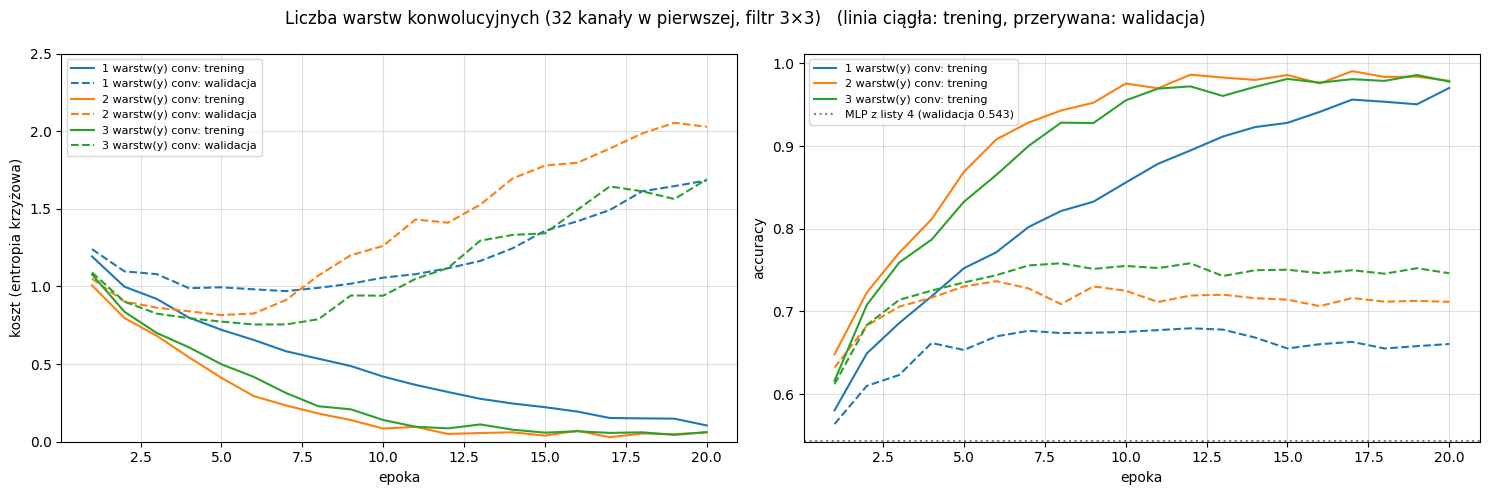

In [10]:
display(summary(scan_runs["n_conv"]))
plot_runs(scan_runs["n_conv"], "Liczba warstw konwolucyjnych (32 kanały w pierwszej, filtr 3×3)", MLP_VAL)

**Wnioski: liczba warstw konwolucyjnych**

- **Więcej warstw konwolucyjnych daje lepszy wynik przy mniejszej liczbie wag:** 1 warstwa 0.680 (2.1 mln wag), 2 warstwy 0.737 (1.07 mln),
  3 warstwy **0.758** (0.62 mln), najlepiej ze wszystkich konfiguracji w części 1.
- Liczba wag spada, bo większość wag siedzi w pierwszej warstwie liniowej, a każdy MaxPool zmniejsza obrazek 2 razy w każdym wymiarze:
  po 1 warstwie do Linear wchodzi 32 · 16 · 16 = 8192 cech, po 3 warstwach 128 · 4 · 4 = 2048.
- Głębsza sieć „widzi” większy fragment obrazka (filtr 3×3 po dwóch poolingach obejmuje fragment 16×16 oryginału)
  i składa proste wzory (krawędzie) w bardziej złożone (fragmenty obiektów). Jedna warstwa widzi tylko fragmenty 3×3.
- Sieć z 1 warstwą przeucza się najmocniej (różnica accuracy trening/walidacja 0.31), sieć z 3 warstwami najsłabiej (0.23),
  ale overfitting jest we wszystkich: koszt walidacyjny po 20 epokach jest 1.7–2.5 razy wyższy niż jego minimum.
- Czas epoki dla 2 i 3 warstw jest podobny (ok. 18 s), bo kolejne warstwy działają na coraz mniejszych obrazkach.

## 1c. Rozmiar filtra

,parametrów,s / epokę,najlepsze acc walid.,epoka,min koszt walid.,epoka min kosztu,koszt walid. na końcu,acc trening na końcu,acc walid. na końcu,różnica acc tr.−wal.
filtr 3×3,1070794,18.2,0.7366,6,0.816,5,2.028,0.9788,0.7116,0.2672
filtr 5×5,1105098,19.7,0.7334,11,0.808,4,2.027,0.9821,0.7080,0.2741
filtr 7×7,1156554,25.6,0.7264,6,0.853,4,2.219,0.9839,0.7106,0.2733


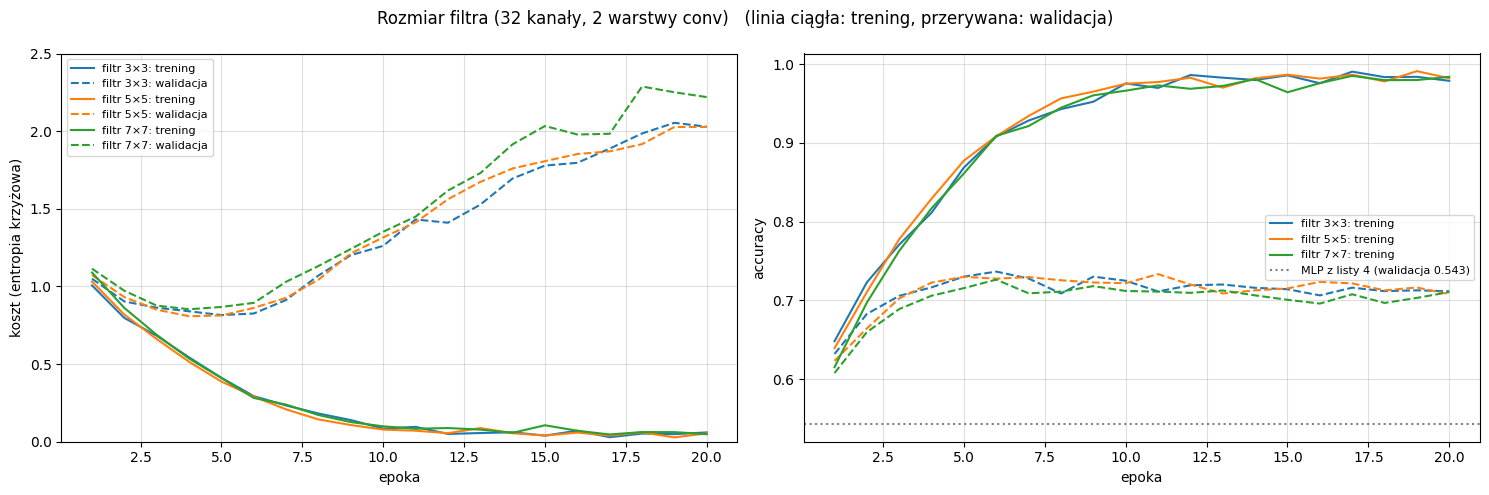

In [11]:
display(summary(scan_runs["kernel"]))
plot_runs(scan_runs["kernel"], "Rozmiar filtra (32 kanały, 2 warstwy conv)", MLP_VAL)

**Wnioski: rozmiar filtra**

- Większy filtr **nie pomaga**: 3×3 daje 0.737, 5×5 0.733, 7×7 0.726, a czas epoki rośnie z 18 s do 26 s.
- Liczba wag prawie się nie zmienia (1.07 → 1.16 mln), bo dominuje warstwa liniowa. Rośnie za to liczba mnożeń w konwolucjach (k²),
  stąd dłuższy czas.
- Dwie warstwy 3×3 i tak widzą razem fragment 5×5 (a z poolingiem jeszcze większy), więc duży filtr nie daje sieci nowych informacji,
  a ma więcej wag do dopasowania. Dlatego standardem są filtry 3×3 i więcej warstw zamiast większych filtrów
  (zgodnie z wynikiem 1b).
- Overfitting jest podobny jak w pozostałych porównaniach (różnica accuracy 0.27; najwyższy koszt na końcu, 2.22, ma filtr 7×7).

## 1d. Zestawienie: wynik a koszt obliczeniowy

,parametrów,s / epokę,najlepsze acc walid.,epoka,min koszt walid.,epoka min kosztu,koszt walid. na końcu,acc trening na końcu,acc walid. na końcu,różnica acc tr.−wal.
3 warstw(y) conv,620362,17.9,0.7582,8,0.755,6,1.690,0.9778,0.7462,0.2316
64 kanałów,2175626,40.1,0.7372,10,0.806,5,2.052,0.9799,0.7132,0.2667
32 kanałów,1070794,18.2,0.7366,6,0.816,5,2.028,0.9788,0.7116,0.2672
filtr 5×5,1105098,19.7,0.7334,11,0.808,4,2.027,0.9821,0.7080,0.2741
filtr 7×7,1156554,25.6,0.7264,6,0.853,4,2.219,0.9839,0.7106,0.2733
16 kanałów,532202,8.4,0.7000,14,0.910,6,2.084,0.9831,0.6908,0.2923
8 kanałów,266362,4.5,0.6800,16,0.966,9,1.590,0.9396,0.6596,0.2800
1 warstw(y) conv,2100874,10.4,0.6796,12,0.970,7,1.683,0.9702,0.6606,0.3096


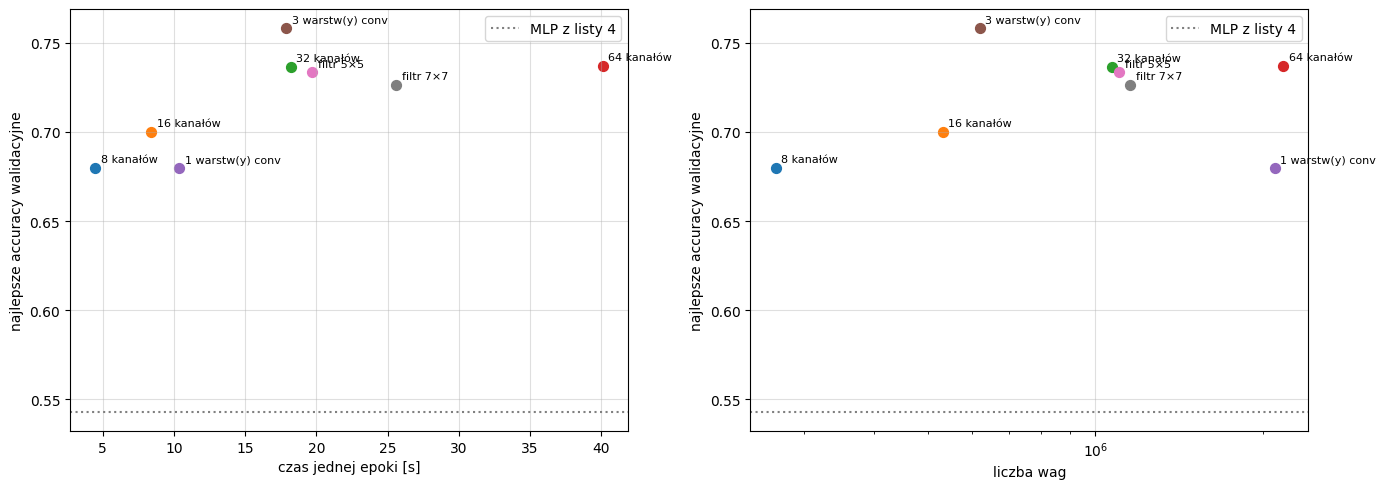

In [12]:
all_p1 = {name: r for runs in scan_runs.values() for name, r in runs.items()}
tab = summary(all_p1).drop_duplicates()
display(tab.sort_values("najlepsze acc walid.", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, row in tab.iterrows():
    for ax, x in zip(axes, ["s / epokę", "parametrów"]):
        ax.scatter(row[x], row["najlepsze acc walid."], s=50)
        ax.annotate(name, (row[x], row["najlepsze acc walid."]), fontsize=8, xytext=(4, 4), textcoords="offset points")
for ax, x in zip(axes, ["czas jednej epoki [s]", "liczba wag"]):
    ax.axhline(MLP_VAL, color="gray", ls=":", label="MLP z listy 4")
    ax.set_xlabel(x); ax.set_ylabel("najlepsze accuracy walidacyjne"); ax.grid(alpha=0.4); ax.legend()
axes[1].set_xscale("log")
fig.tight_layout()
plt.show()

**Wnioski: zestawienie części 1**

- **Każda** przebadana sieć konwolucyjna jest wyraźnie lepsza od MLP z listy 4 (0.68–0.76 wobec 0.543 accuracy walidacyjnego),
  a większość ma przy tym mniej wag.
- Najlepszy stosunek wyniku do kosztu ma **więcej warstw** (3 warstwy: najlepszy wynik, najmniej wag, 18 s na epokę).
  Więcej kanałów pomaga do 32, potem głównie wydłuża uczenie. Większy filtr tylko wydłuża uczenie.
- Do części 2 zostawiam referencję (32 kanały, 2 warstwy, 3×3), a nie najlepszą sieć z 3 warstwami.
  Ma tę samą szybkość, a overfitting jest u niej silniejszy (różnica 0.27, koszt walidacyjny rośnie od 0.82 do 2.03), więc lepiej widać, ile daje regularyzacja.
- Czasy w tabelach są orientacyjne: ta sama sieć raz miała 18.2 s, a w części 2 (Dropout, ta sama liczba obliczeń) 15 s.
  Różnice rzędu 20% to wpływ innych programów działających na komputerze.

---
# CZĘŚĆ 2 – regularyzacja

Sieć: konfiguracja referencyjna z części 1 (32 kanały, 2 warstwy, 3×3). Bez regularyzacji koszt walidacyjny wyraźnie rośnie,
a accuracy treningowe odjeżdża od walidacyjnego, więc jest co poprawiać, a uczenie jest tanie.

| technika | co robi | trening | ewaluacja |
|---|---|---|---|
| **Dropout(p)** przed ostatnią warstwą | losowo zeruje ułamek p neuronów warstwy ukrytej (resztę mnoży przez 1/(1−p)), więc sieć nie może polegać na pojedynczych neuronach | losowe zerowanie | nic nie robi |
| **AdamW(weight_decay)** | po każdym kroku ADAM dodatkowo zmniejsza wagi: w ← w − lr · wd · w, co trzyma wagi małe | tak samo | — |
| **BatchNorm2d** po każdej konwolucji | normalizuje każdy kanał do średniej 0 i wariancji 1 (potem uczona skala i przesunięcie) | statystyki z bieżącej paczki, aktualizuje średnie kroczące | używa średnich kroczących |

Dropout i BatchNorm działają inaczej w trybie `train` i `eval`, dlatego metryki liczę zawsze po `model.eval()`
(funkcja `evaluate`), a uczenie zawsze po `model.train()` (funkcja `fit`).

## Sprawdzenie: AdamW to ADAM plus osobne zmniejszanie wag

W `torch.optim.Adam` też jest parametr `weight_decay`, ale działa inaczej: dodaje wd · w do gradientu, który potem jest
skalowany przez adaptacyjny mianownik ADAM. AdamW odejmuje lr · wd · w od wag osobno. Sprawdzam to na jednym kroku:

In [13]:
torch.manual_seed(0)
w0 = torch.randn(5, requires_grad=True)
X_, y_ = torch.randn(8, 5), torch.randn(8)

def one_step(opt_cls, **kw):
    w = w0.detach().clone().requires_grad_(True)
    opt = opt_cls([w], lr=1e-3, **kw)
    ((X_ @ w - y_) ** 2).mean().backward()
    opt.step()
    return w.detach()

w_adam = one_step(torch.optim.Adam)
w_adamw = one_step(torch.optim.AdamW, weight_decay=0.1)
w_adamw0 = one_step(torch.optim.AdamW, weight_decay=0.0)
w_adam_l2 = one_step(torch.optim.Adam, weight_decay=0.1)
print("AdamW(wd=0) == Adam:                         ", torch.equal(w_adamw0, w_adam))
print("AdamW(wd=0.1) == Adam − lr·wd·w0, max różnica:", (w_adamw - (w_adam - 1e-3 * 0.1 * w0.detach())).abs().max().item())
print("Adam(weight_decay=0.1) daje coś innego:       ", (w_adam_l2 - w_adamw).abs().max().item())

AdamW(wd=0) == Adam:                          True
AdamW(wd=0.1) == Adam − lr·wd·w0, max różnica: 0.0
Adam(weight_decay=0.1) daje coś innego:        0.00021791458129882812


## Warianty

Każdy wariant na seedzie 0, 20 epok, ta sama sieć i ta sama kolejność paczek. Wariant bez regularyzacji to referencja z części 1
(już policzona). Dla Dropout i AdamW sprawdzam po dwie siły. Przy lr = 0.001 i ok. 7000 kroków weight decay 0.1 zmniejsza wagi
(bez gradientu) o czynnik e^(−0.7) ≈ 0.5, a 0.5 o czynnik e^(−3.5) ≈ 0.03, więc to już duża siła. Na koniec łączę wszystkie trzy techniki.

In [14]:
REG = {"bez regularyzacji": {},
       "Dropout p = 0.3": dict(dropout=0.3),
       "Dropout p = 0.5": dict(dropout=0.5),
       "AdamW wd = 0.1": dict(wd=0.1),
       "AdamW wd = 0.5": dict(wd=0.5),
       "BatchNorm": dict(batchnorm=True),
       "BatchNorm + Dropout 0.5 + AdamW 0.1": dict(batchnorm=True, dropout=0.5, wd=0.1)}

reg_runs = {name: run({**REF, **cfg}) for name, cfg in REG.items()}
reg_tab = summary(reg_runs)
display(reg_tab)

{'channels': 32, 'n_conv': 2, 'kernel': 3, 'dropout': 0.3} seed 0: najlepsze acc walid. 0.7416 (epoka 17), 345 s


{'channels': 32, 'n_conv': 2, 'kernel': 3, 'dropout': 0.5} seed 0: najlepsze acc walid. 0.7432 (epoka 11), 341 s


{'channels': 32, 'n_conv': 2, 'kernel': 3, 'wd': 0.1} seed 0: najlepsze acc walid. 0.7350 (epoka 7), 353 s


{'channels': 32, 'n_conv': 2, 'kernel': 3, 'wd': 0.5} seed 0: najlepsze acc walid. 0.7346 (epoka 12), 355 s


{'channels': 32, 'n_conv': 2, 'kernel': 3, 'batchnorm': True} seed 0: najlepsze acc walid. 0.7464 (epoka 14), 426 s


{'channels': 32, 'n_conv': 2, 'kernel': 3, 'batchnorm': True, 'dropout': 0.5, 'wd': 0.1} seed 0: najlepsze acc walid. 0.7502 (epoka 19), 421 s


,parametrów,s / epokę,najlepsze acc walid.,epoka,min koszt walid.,epoka min kosztu,koszt walid. na końcu,acc trening na końcu,acc walid. na końcu,różnica acc tr.−wal.
bez regularyzacji,1070794,18.2,0.7366,6,0.816,5,2.028,0.9788,0.7116,0.2672
Dropout p = 0.3,1070794,15.0,0.7416,17,0.783,5,1.271,0.9943,0.7348,0.2595
Dropout p = 0.5,1070794,14.9,0.7432,11,0.775,10,1.058,0.9791,0.7362,0.2429
AdamW wd = 0.1,1070794,15.4,0.7350,7,0.803,5,1.414,0.9842,0.7148,0.2694
AdamW wd = 0.5,1070794,15.5,0.7346,12,0.774,12,0.842,0.9425,0.7240,0.2185
BatchNorm,1070986,18.8,0.7464,14,0.803,6,1.402,0.9806,0.7374,0.2432
BatchNorm + Dropout 0.5 + AdamW 0.1,1070986,18.5,0.7502,19,0.732,19,0.754,0.8651,0.7408,0.1243


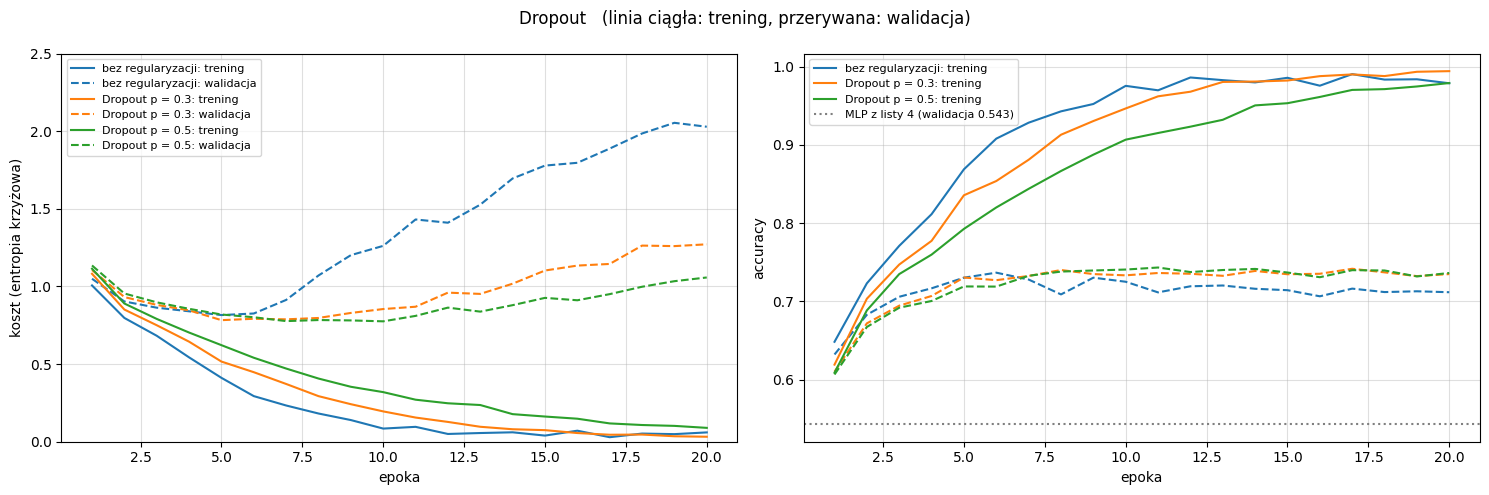

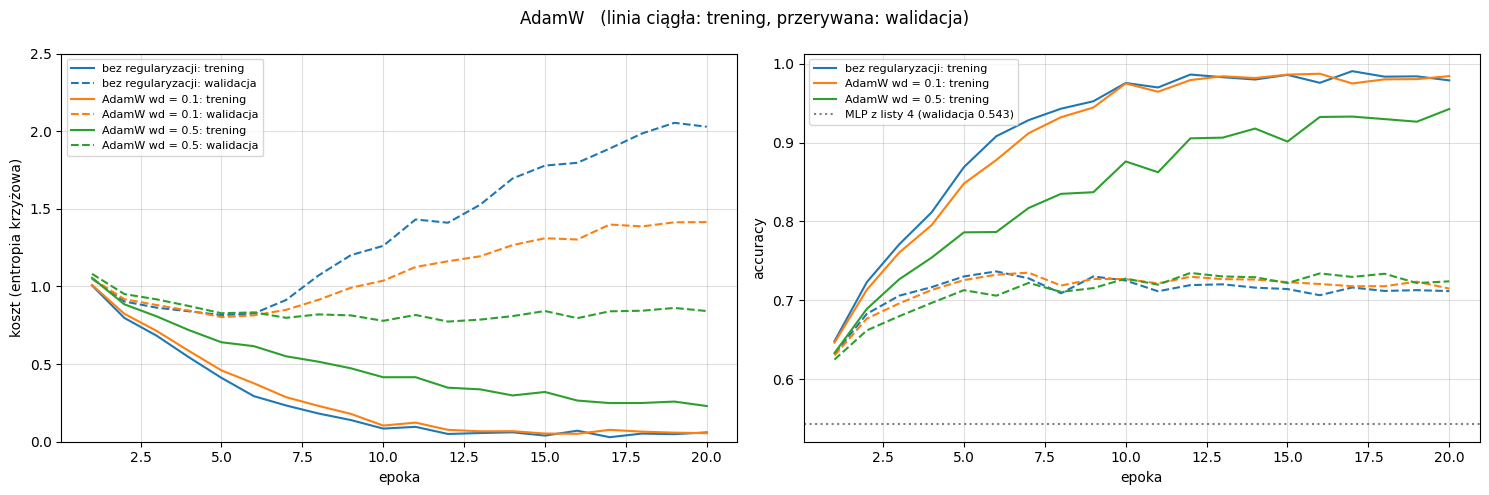

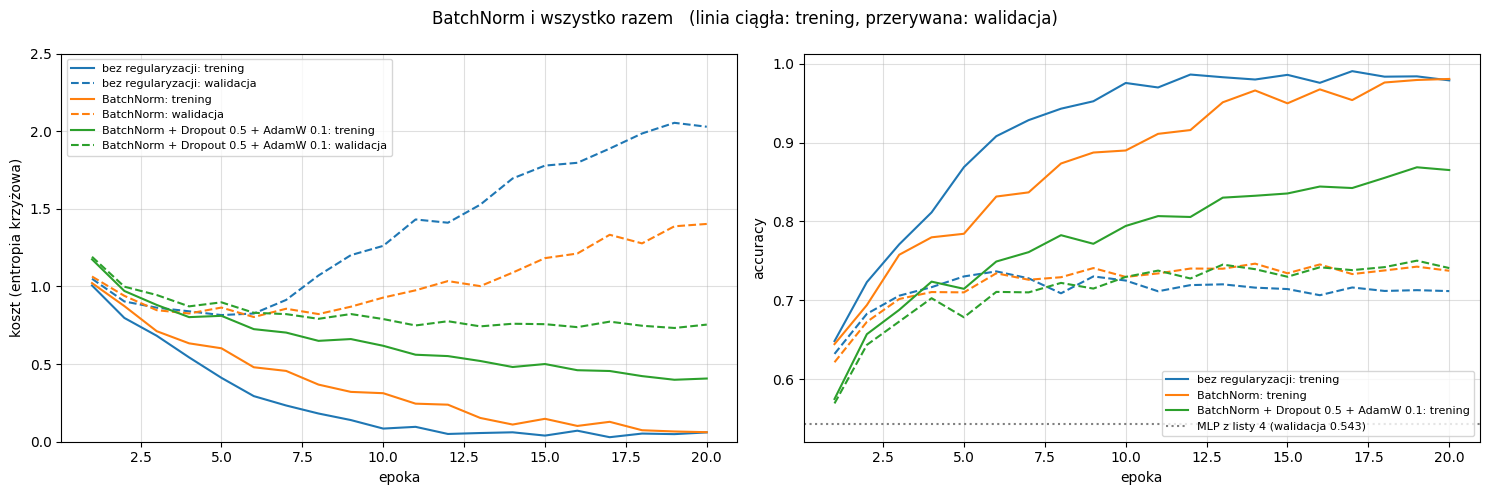

In [15]:
groups = {"Dropout": ["bez regularyzacji", "Dropout p = 0.3", "Dropout p = 0.5"],
          "AdamW": ["bez regularyzacji", "AdamW wd = 0.1", "AdamW wd = 0.5"],
          "BatchNorm i wszystko razem": ["bez regularyzacji", "BatchNorm", "BatchNorm + Dropout 0.5 + AdamW 0.1"]}
for title, names in groups.items():
    plot_runs({n: reg_runs[n] for n in names}, title, MLP_VAL)

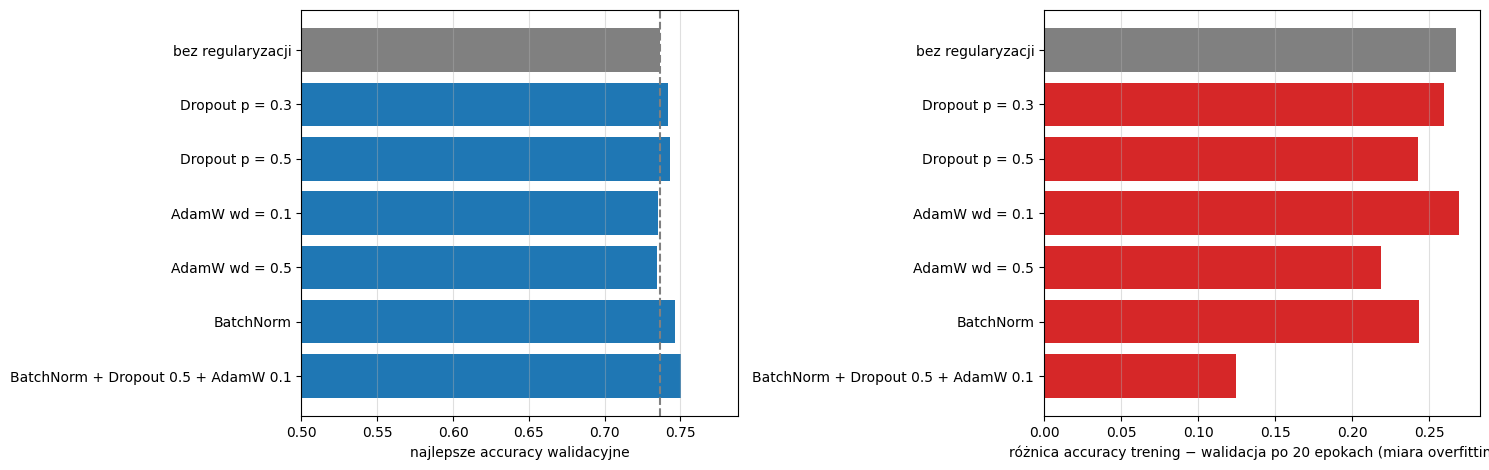

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
names = list(reg_tab.index)
base_acc = reg_tab.loc["bez regularyzacji", "najlepsze acc walid."]
axes[0].barh(names, reg_tab["najlepsze acc walid."], color=["gray"] + ["C0"] * (len(names) - 1))
axes[0].axvline(base_acc, color="gray", ls="--")
axes[0].set_xlim(0.5, None); axes[0].set_xlabel("najlepsze accuracy walidacyjne")
axes[1].barh(names, reg_tab["różnica acc tr.−wal."], color=["gray"] + ["C3"] * (len(names) - 1))
axes[1].set_xlabel("różnica accuracy trening − walidacja po 20 epokach (miara overfittingu)")
for ax in axes:
    ax.invert_yaxis(); ax.grid(alpha=0.4, axis="x")
fig.tight_layout()
plt.show()

**Wnioski: regularyzacja (seed 0)**

| wariant | najlepsze acc walid. | zmiana | różnica acc tr.−wal. | koszt walid.: minimum → po 20 epokach |
|---|---|---|---|---|
| bez regularyzacji | 0.7366 | — | 0.267 | 0.816 → 2.028 |
| Dropout 0.3 | 0.7416 | +0.005 | 0.260 | 0.783 → 1.271 |
| Dropout 0.5 | 0.7432 | +0.007 | 0.243 | 0.775 → 1.058 |
| AdamW 0.1 | 0.7350 | −0.002 | 0.269 | 0.803 → 1.414 |
| AdamW 0.5 | 0.7346 | −0.002 | 0.219 | 0.774 → 0.842 |
| BatchNorm | 0.7464 | +0.010 | 0.243 | 0.803 → 1.402 |
| **BatchNorm + Dropout 0.5 + AdamW 0.1** | **0.7502** | **+0.014** | **0.124** | **0.732 → 0.754** |

- **Każda technika osobno hamuje wzrost kosztu walidacyjnego** (2.03 bez regularyzacji, 0.84–1.41 z regularyzacją),
  ale accuracy poprawia tylko trochę: Dropout o 0.005–0.007, BatchNorm o 0.010.
- **AdamW** najmocniej spłaszcza koszt walidacyjny (wd = 0.5: 0.77 → 0.84) i zmniejsza różnicę trening/walidacja (0.22),
  ale accuracy nie rośnie (−0.002). Małe wagi dają mniej „pewne siebie” predykcje, więc koszt rośnie wolniej,
  ale same decyzje sieci prawie się nie zmieniają. Przy wd = 0.1 efekt jest słaby.
- **Dropout** sprawia, że najlepsza epoka przesuwa się na później (11–17 zamiast 6). Sieć uczy się dłużej, zanim zacznie się przeuczać.
- **Wszystkie trzy techniki razem** to jedyny wariant, w którym overfitting praktycznie znika: koszt walidacyjny spada
  prawie do końca (minimum 0.732 w 19. epoce, na końcu 0.754), różnica trening/walidacja spadła z 0.27 do 0.12
  (accuracy treningowe 0.87 zamiast 0.98), a accuracy walidacyjne jest najlepsze (**0.750**, +0.014). Najlepsza epoka to 19 z 20,
  więc ta sieć skorzystałaby jeszcze z dłuższego uczenia.
- Są to wyniki z jednego seeda, a różnice w pojedynczych wariantach to 0.5–1 punktu procentowego. Dlatego najlepszy wariant
  sprawdzam niżej na 3 seedach.

## Sprawdzenie: co się dzieje, gdy zapomni się o `model.eval()`

Biorę nauczony model z Dropout i BatchNorm i liczę accuracy walidacyjne dwa razy w trybie `eval` i dwa razy w trybie `train`
(na kopii modelu, bo w trybie `train` BatchNorm nadpisuje swoje średnie kroczące, nawet w `no_grad`).

In [17]:
def acc_in_mode(model, mode):
    m = copy.deepcopy(model)
    m.train(mode == "train")
    with torch.no_grad():
        preds = torch.cat([m(X).argmax(1) for X, _ in val_loader])
    return (preds == val_ds.tensors[1]).float().mean().item()

model_reg = reg_runs["BatchNorm + Dropout 0.5 + AdamW 0.1"]["model"]
for mode in ["eval", "eval", "train", "train"]:
    print(f"tryb {mode:<5}: accuracy walidacyjne {acc_in_mode(model_reg, mode):.4f}")

tryb eval : accuracy walidacyjne 0.7502


tryb eval : accuracy walidacyjne 0.7502


tryb train: accuracy walidacyjne 0.7024


tryb train: accuracy walidacyjne 0.7028


**Wniosek:** w trybie `eval` wynik jest powtarzalny (dwa razy dokładnie 0.7502). W trybie `train` jest **o ok. 5 punktów procentowych gorszy**
(0.702–0.703) i za każdym razem trochę inny. Dropout losowo wyłącza połowę neuronów, a BatchNorm normalizuje paczką walidacyjną
zamiast średnimi z treningu. Bez `model.eval()` metryki byłyby więc zaniżone i zaszumione, a porównanie wariantów z regularyzacją
i bez niej byłoby niesprawiedliwe.

## Wynik końcowy: 3 seedy, zbiór testowy

Porównuję sieć bez regularyzacji i najlepszy wariant regularyzacji (według accuracy walidacyjnego) na seedach 0, 1, 2.
Każdy model ma wagi z epoki o najlepszym accuracy walidacyjnym. Zbiór testowy jest użyty pierwszy raz dopiero tutaj.

In [18]:
best_reg = reg_tab.drop("bez regularyzacji")["najlepsze acc walid."].astype(float).idxmax()
print("najlepsza regularyzacja na walidacji:", best_reg)

rows, final = [], {}
for name in ["bez regularyzacji", best_reg]:
    for seed in [0, 1, 2]:
        r = run({**REF, **REG[name]}, seed)
        tl, ta, preds = evaluate(test_loader, r["model"])
        final[(name, seed)] = preds
        rows.append({"wariant": name, "seed": seed, "epoka": r["best_epoch"], "acc walid.": round(r["best_acc"], 4),
                     "acc test": round(ta, 4), "koszt test": round(tl, 4)})
res = pd.DataFrame(rows)
display(res.set_index(["wariant", "seed"]))
def std(s): return s.std(ddof=0)
agg = res.groupby("wariant", sort=False)[["acc walid.", "acc test"]].agg(["mean", std]).round(4)
display(agg)

najlepsza regularyzacja na walidacji: BatchNorm + Dropout 0.5 + AdamW 0.1


{'channels': 32, 'n_conv': 2, 'kernel': 3} seed 1: najlepsze acc walid. 0.7314 (epoka 6), 335 s


{'channels': 32, 'n_conv': 2, 'kernel': 3} seed 2: najlepsze acc walid. 0.7322 (epoka 6), 338 s


{'channels': 32, 'n_conv': 2, 'kernel': 3, 'batchnorm': True, 'dropout': 0.5, 'wd': 0.1} seed 1: najlepsze acc walid. 0.7718 (epoka 18), 442 s


{'channels': 32, 'n_conv': 2, 'kernel': 3, 'batchnorm': True, 'dropout': 0.5, 'wd': 0.1} seed 2: najlepsze acc walid. 0.7560 (epoka 19), 443 s


epoka  acc walid.  acc test  koszt test
wariant                             seed                                         
bez regularyzacji                   0         6      0.7366    0.7317      0.8459
                                    1         6      0.7314    0.7234      0.8573
                                    2         6      0.7322    0.7256      0.8309
BatchNorm + Dropout 0.5 + AdamW 0.1 0        19      0.7502    0.7472      0.7394
                                    1        18      0.7718    0.7591      0.7029
                                    2        19      0.7560    0.7536      0.7281

acc walid.         acc test        
                                          mean     std     mean     std
wariant                                                                
bez regularyzacji                       0.7334  0.0023   0.7269  0.0035
BatchNorm + Dropout 0.5 + AdamW 0.1     0.7593  0.0091   0.7533  0.0049

## Porównanie z baseline'em z listy 4 (MLP)

Wczytuję zapisane wagi MLP z listy 4 (`lab4/cifar10_mlp.pth`, seed 0) i liczę accuracy każdej klasy na tym samym zbiorze testowym.

In [19]:
class CifarNet(nn.Module):                      # MLP z listy 4 (ta sama definicja)
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(nn.Linear(3 * 32 * 32, 512), nn.ReLU(),
                                               nn.Linear(512, 512), nn.ReLU(), nn.Linear(512, 10))
    def forward(self, x):
        return self.linear_relu_stack(self.flatten(x))

mlp = CifarNet()
mlp.load_state_dict(torch.load("../lab4/cifar10_mlp.pth"))
_, mlp_acc, mlp_preds = evaluate(test_loader, mlp)

per_class = lambda p: (confusion_matrix(yc_test.numpy(), p.numpy()).diagonal() / 1000).round(3)
cmp = pd.DataFrame({"MLP (lista 4)": per_class(mlp_preds),
                    "CNN bez regularyzacji": per_class(final[("bez regularyzacji", 0)]),
                    f"CNN {best_reg}": per_class(final[(best_reg, 0)])}, index=classes)
cmp.loc["ŚREDNIO"] = cmp.mean().round(4)
display(cmp)

summary_tab = pd.DataFrame({
    "accuracy testowe (3 seedy)": [f"{0.5335:.4f} ± 0.0027"] + [
        f"{res[res.wariant == n]['acc test'].mean():.4f} ± {res[res.wariant == n]['acc test'].std(ddof=0):.4f}"
        for n in ["bez regularyzacji", best_reg]],
    "parametrów": [n_params(mlp), reg_runs["bez regularyzacji"]["params"], reg_runs[best_reg]["params"]]},
    index=["MLP 3072-512-512-10 (lista 4)", "CNN bez regularyzacji", f"CNN {best_reg}"])
display(summary_tab)
print(f"MLP z pliku, seed 0: accuracy testowe {mlp_acc:.4f} (lista 4: 0.5297)")

torch.save(run({**REF, **REG[best_reg]}, 0)["model"].state_dict(), "cifar10_cnn.pth")

,MLP (lista 4),CNN bez regularyzacji,CNN BatchNorm + Dropout 0.5 + AdamW 0.1
airplane,0.6250,0.7900,0.7760
automobile,0.6250,0.7980,0.7930
bird,0.4210,0.5610,0.5860
cat,0.3170,0.4930,0.5930
deer,0.4260,0.6610,0.7460
dog,0.4150,0.6970,0.6050
frog,0.6300,0.8520,0.8520
horse,0.5950,0.8010,0.7540
ship,0.6620,0.8580,0.8450
truck,0.5810,0.8060,0.9220


,accuracy testowe (3 seedy),parametrów
MLP 3072-512-512-10 (lista 4),0.5335 ± 0.0027,1841162
CNN bez regularyzacji,0.7269 ± 0.0035,1070794
CNN BatchNorm + Dropout 0.5 + AdamW 0.1,0.7533 ± 0.0049,1070986


MLP z pliku, seed 0: accuracy testowe 0.5297 (lista 4: 0.5297)


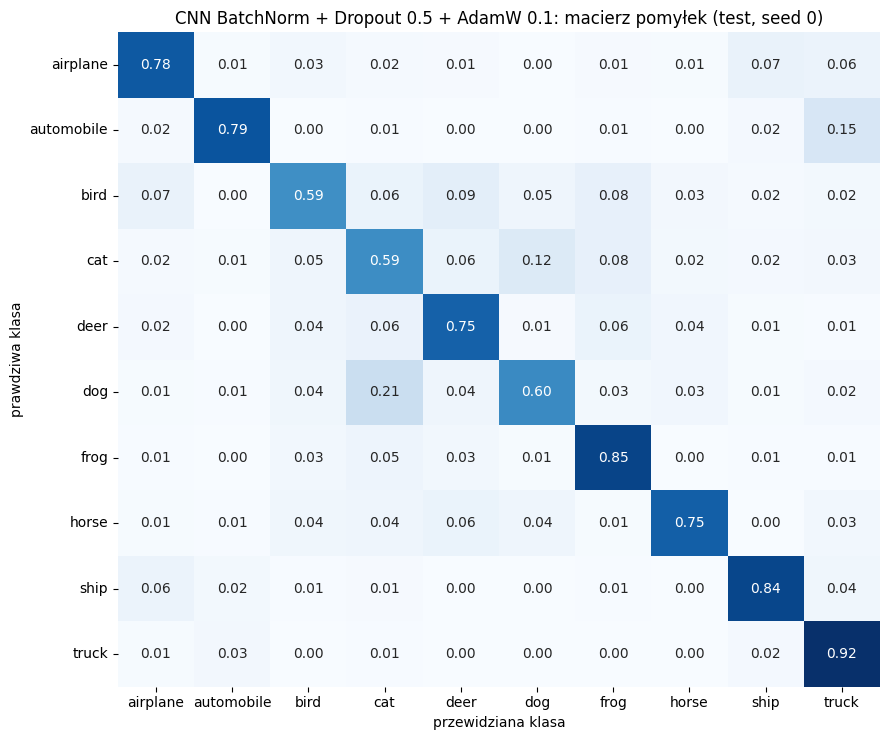

In [20]:
cm = confusion_matrix(yc_test.numpy(), final[(best_reg, 0)].numpy())
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", xticklabels=classes,
            yticklabels=classes, cbar=False, ax=ax)
ax.set_xlabel("przewidziana klasa"); ax.set_ylabel("prawdziwa klasa")
ax.set_title(f"CNN {best_reg}: macierz pomyłek (test, seed 0)")
fig.tight_layout()
plt.show()

# Wnioski

## Część 1: sieć konwolucyjna a MLP z listy 4

| model | parametrów | accuracy testowe (3 seedy) |
|---|---|---|
| MLP 3072-512-512-10 (lista 4) | 1 841 162 | 0.5335 ± 0.0027 |
| CNN 32 kanały, 2 warstwy, 3×3 | 1 070 794 | 0.7269 ± 0.0035 |
| CNN + BatchNorm + Dropout 0.5 + AdamW 0.1 | 1 070 986 | **0.7533 ± 0.0049** |

1. **Już prosta sieć konwolucyjna poprawia baseline z listy 4 o ok. 19 punktów procentowych** (0.533 → 0.727) przy prawie 2 razy mniejszej liczbie wag.
   Filtr konwolucyjny ma kilka–kilkadziesiąt wag i używa ich w każdym miejscu obrazka, a MLP musi się osobno uczyć każdego piksela w każdym położeniu.
   CNN jest lepsza we wszystkich 10 klasach. Najtrudniejsze dalej są kot i ptak (accuracy 0.49–0.59), tak jak w liście 4.
2. **Liczba warstw konwolucyjnych** ma największy wpływ: 1 → 2 → 3 warstwy to 0.680 → 0.737 → 0.758 na walidacji, przy coraz mniejszej liczbie wag.
   **Liczba kanałów** pomaga do 32 (0.680 → 0.737), potem głównie wydłuża uczenie (64 kanały: +0.001 za 2 razy dłuższą epokę).
   **Większy filtr** nie pomaga (3×3 0.737, 5×5 0.733, 7×7 0.726) i tylko wydłuża uczenie.
3. **Overfitting widać w każdej konfiguracji:** koszt walidacyjny ma minimum w 4.–9. epoce i potem rośnie 1.6–2.6 razy, a accuracy treningowe dochodzi do 0.94–0.98 przy 0.66–0.75 na walidacji.
   ADAM z lr = 0.001 i 20 epok wystarczają, żeby go wyraźnie pokazać przy koszcie 2–15 minut na sieć na CPU.

## Część 2: regularyzacja

4. Każda technika osobno zmniejsza wzrost kosztu walidacyjnego, ale accuracy walidacyjne poprawia o najwyżej 1 punkt procentowy
   (Dropout +0.5–0.7, BatchNorm +1.0, AdamW bez poprawy).
5. **Połączenie BatchNorm + Dropout 0.5 + AdamW 0.1 daje faktyczną redukcję overfittingu, która przekłada się na lepszy wynik:**
   - różnica accuracy trening/walidacja 0.12 zamiast 0.27, a koszt walidacyjny prawie nie rośnie do końca uczenia (0.73 → 0.75 zamiast 0.82 → 2.03);
   - na 3 seedach accuracy walidacyjne 0.759 ± 0.009 wobec 0.733 ± 0.002, **testowe 0.753 ± 0.005 wobec 0.727 ± 0.004** (+2.6 punktu procentowego,
     poprawa na każdym seedzie, różnica dużo większa niż rozrzut między seedami);
   - koszt testowy 0.70–0.74 zamiast 0.83–0.86.
6. Sieć bez regularyzacji najlepsze accuracy osiąga w 6. epoce, a dalsze uczenie tylko szkodzi. Sieć z regularyzacją w 18.–19. epoce i dalej się poprawia,
   więc przy dłuższym uczeniu zysk byłby prawdopodobnie jeszcze większy.
7. Tryby `train` / `eval` mają realne znaczenie: ta sama nauczona sieć liczona w trybie `train` ma accuracy walidacyjne o ok. 5 punktów procentowych niższe (0.703 zamiast 0.750).

Wagi najlepszego modelu (regularyzacja, seed 0) są zapisane w `cifar10_cnn.pth`.